#Victoria Road Crash Data EDA

Road crashes cause deaths and injuries every day. Our project, Road Safety, wants to find where and when crashes happen, what makes them more serious, and how emergency teams can reach them faster.

This notebook goes through the main flat file, `victorian_road_crash_data.csv`.
It does the following:
1. Checks the data quality
2. Decides which columns we need and which we do not
3. Shows the first findings
4. Lists the research questions this file can answer, and the ones it cannot

##Research questions this dataset can answer

1. Where are the crash hotspots?
2. When do crashes happen?
3. What makes a crash more serious?
4. Which road users are at most risk?
5. Do road and place matter?
6. Can we predict how severe a crash will be?
7. Where should ambulances be placed and which routes should they use?

#1. Load the data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving victorian_road_crash_data.csv to victorian_road_crash_data (2).csv


In [ ]:
df = pd.read_csv('victorian_road_crash_data.csv')

In [ ]:
df.head(3)

,ACCIDENT_NO,ACCIDENT_DATE,ACCIDENT_TIME,ACCIDENT_TYPE,DAY_OF_WEEK,DCA_CODE,DCA_CODE_DESCRIPTION,LIGHT_CONDITION,POLICE_ATTEND,ROAD_GEOMETRY,...,NO_OF_VEHICLES,HEAVYVEHICLE,PASSENGERVEHICLE,MOTORCYCLE,PT_VEHICLE,DEG_URBAN_NAME,SRNS,RMA,DIVIDED,STAT_DIV_NAME
0,T20140024624,2014-11-27,18:35:00,Collision with vehicle,Thursday,110,CROSS TRAFFIC(INTERSECTIONS ONLY),Day,Yes,Cross intersection,...,2.0,0.0,2.0,0.0,0.0,TOWNS,NaN,Local Road,Undivided,Country
1,T20190026336,2019-12-27,15:45:00,Collision with vehicle,Friday,113,RIGHT NEAR (INTERSECTIONS ONLY),Day,Yes,T intersection,...,2.0,0.0,2.0,0.0,0.0,MELB_URBAN,NaN,Arterial Other,Divided,Metro
2,T20190019196,2019-10-02,12:07:00,Collision with vehicle,Wednesday,173,RIGHT OFF CARRIAGEWAY INTO OBJECT/PARKED VEHICLE,Day,Yes,Not at intersection,...,3.0,0.0,2.0,0.0,0.0,MELB_URBAN,M,Freeway,Divided,Metro


#2. Data quality

In [ ]:
print('Data Shape:',df.shape)

Data Shape: (202554, 52)


In [ ]:
df.isna().sum()

,0
ACCIDENT_NO,0
ACCIDENT_DATE,0
ACCIDENT_TIME,0
ACCIDENT_TYPE,0
DAY_OF_WEEK,0
DCA_CODE,0
DCA_CODE_DESCRIPTION,0
LIGHT_CONDITION,0
POLICE_ATTEND,0
ROAD_GEOMETRY,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202554 entries, 0 to 202553
Data columns (total 52 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   ACCIDENT_NO             202554 non-null  object 
 1   ACCIDENT_DATE           202554 non-null  object 
 2   ACCIDENT_TIME           202554 non-null  object 
 3   ACCIDENT_TYPE           202554 non-null  object 
 4   DAY_OF_WEEK             202554 non-null  object 
 5   DCA_CODE                202554 non-null  int64  
 6   DCA_CODE_DESCRIPTION    202554 non-null  object 
 7   LIGHT_CONDITION         202554 non-null  object 
 8   POLICE_ATTEND           202554 non-null  object 
 9   ROAD_GEOMETRY           202554 non-null  object 
 10  SEVERITY                202554 non-null  object 
 11  SPEED_ZONE              202554 non-null  object 
 12  RUN_OFFROAD             202554 non-null  object 
 13  ROAD_NAME               201100 non-null  object 
 14  ROAD_TYPE           

What this tells us

- No duplicate crashes, which is good
- 1,275 crashes have no location, so they cannot go on a map. About 1,190 of them are from 2025, so recent crashes are probably not yet located. Hotspot maps will show fewer 2025 crashes than really happened

#3. Data cleaning

In [ ]:
drop_cols = [
    'DAY_OF_WEEK', 'DCA_CODE', 'DCA_CODE_DESCRIPTION', 'POLICE_ATTEND', 'RUN_OFFROAD',
    'ROAD_NAME', 'ROAD_TYPE', 'ROAD_ROUTE_1', 'DTP_REGION', 'STAT_DIV_NAME', 'SRNS',
    'VICGRID_X', 'VICGRID_Y', 'MALES', 'FEMALES', 'DRIVER', 'PASSENGER', 'PILLION',
    'UNKNOWN', 'PED_CYCLIST_5_12', 'PED_CYCLIST_13_18', 'PASSENGERVEHICLE', 'PT_VEHICLE',
]

df = df.drop(columns=drop_cols).dropna(subset=['LATITUDE', 'LONGITUDE', 'NO_OF_VEHICLES', 'HEAVYVEHICLE', 'MOTORCYCLE'])

print(df.shape)

(201269, 29)


In [ ]:
df.SPEED_ZONE

,SPEED_ZONE
0,50 km/hr
1,60 km/hr
2,100 km/hr
3,80 km/hr
4,80 km/hr
...,...
202204,60 km/hr
202205,80 km/hr
202206,60 km/hr
202207,50 km/hr


In [ ]:
text_cols = ['LGA_NAME', 'DEG_URBAN_NAME', 'RMA', 'DIVIDED']
df[text_cols] = df[text_cols].fillna('Unknown')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 201269 entries, 0 to 202208
Data columns (total 29 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   ACCIDENT_NO             201269 non-null  object 
 1   ACCIDENT_DATE           201269 non-null  object 
 2   ACCIDENT_TIME           201269 non-null  object 
 3   ACCIDENT_TYPE           201269 non-null  object 
 4   LIGHT_CONDITION         201269 non-null  object 
 5   ROAD_GEOMETRY           201269 non-null  object 
 6   SEVERITY                201269 non-null  object 
 7   SPEED_ZONE              201269 non-null  object 
 8   LGA_NAME                201269 non-null  object 
 9   LATITUDE                201269 non-null  float64
 10  LONGITUDE               201269 non-null  float64
 11  TOTAL_PERSONS           201269 non-null  int64  
 12  INJ_OR_FATAL            201269 non-null  int64  
 13  FATALITY                201269 non-null  int64  
 14  SERIOUSINJURY           2

In [ ]:
df['ACCIDENT_DATE'] = pd.to_datetime(df['ACCIDENT_DATE'])

In [ ]:
df['year'] = df['ACCIDENT_DATE'].dt.year
df['month'] = df['ACCIDENT_DATE'].dt.month
df['day_name'] = df['ACCIDENT_DATE'].dt.day_name()
df['hour'] = pd.to_datetime(df['ACCIDENT_TIME'].astype(str), format='mixed').dt.hour

In [ ]:
df['severity'] = df['SEVERITY'].replace({'Fatal accident': 'Fatal',
                                         'Serious injury accident': 'Serious injury',
                                         'Other injury accident': 'Other injury',
                                         'Non injury accident': 'No injury'})

In [ ]:
df['speed'] = pd.to_numeric(df['SPEED_ZONE'].str.extract(r'(\d+)')[0], errors='coerce')

In [ ]:
df = df.drop(columns=['ACCIDENT_TIME', 'SEVERITY', 'SPEED_ZONE'])

In [ ]:
df.head(5)

,ACCIDENT_NO,ACCIDENT_DATE,ACCIDENT_TYPE,LIGHT_CONDITION,ROAD_GEOMETRY,LGA_NAME,LATITUDE,LONGITUDE,TOTAL_PERSONS,INJ_OR_FATAL,...,MOTORCYCLE,DEG_URBAN_NAME,RMA,DIVIDED,year,month,day_name,hour,severity,speed
0,T20140024624,2014-11-27,Collision with vehicle,Day,Cross intersection,WELLINGTON,-37.961970,146.98431,3,1,...,0.0,TOWNS,Local Road,Undivided,2014,11,Thursday,18,Other injury,50.0
1,T20190026336,2019-12-27,Collision with vehicle,Day,T intersection,BANYULE,-37.748672,145.04663,3,1,...,0.0,MELB_URBAN,Arterial Other,Divided,2019,12,Friday,15,Other injury,60.0
2,T20190019196,2019-10-02,Collision with vehicle,Day,Not at intersection,BRIMBANK,-37.728622,144.85841,5,1,...,0.0,MELB_URBAN,Freeway,Divided,2019,10,Wednesday,12,Other injury,100.0
3,T20250029202,2025-11-07,Struck Pedestrian,Day,Not at intersection,KNOX,-37.926075,145.23350,2,1,...,0.0,MELB_URBAN,Arterial Highway,Divided,2025,11,Friday,13,Serious injury,80.0
4,T20210005363,2021-01-30,Collision with a fixed object,Dusk/Dawn,Not at intersection,CARDINIA,-37.905216,145.59479,1,1,...,0.0,RURAL_VICTORIA,Arterial Other,Undivided,2021,1,Saturday,6,Serious injury,80.0


#5. Analysis & Findings

In [ ]:
sns.set_style('whitegrid')

##5.1 How severe are the crashes?

Percentage Crash Severity: severity
Other injury      62.4
Serious injury    35.9
Fatal              1.7
No injury          0.0
Name: count, dtype: float64


Text(0, 0.5, 'Count')

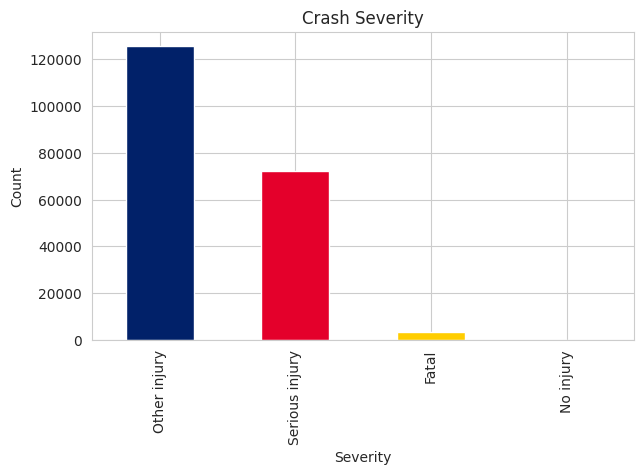

In [ ]:
sev = df['severity'].value_counts()
print('Percentage Crash Severity:',(sev / len(df) * 100).round(1))

ax = sev.plot(kind='bar', color=['#012169', '#E4002B', '#00843D'], figsize=(7, 4))
ax.set_title('Crash Severity')
ax.set_xlabel('Severity')
ax.set_ylabel('Count')

**Finding:** Almost every crash in this file involves an injury (only 4 have no injury). Fatal crashes are about 1.7% of the total, so models must handle very uneven classes.

##5.2 Crashes over the years

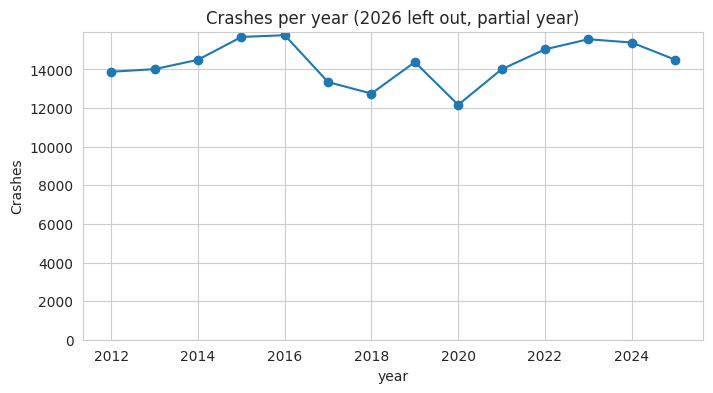

,0
year,
2012,13881
2013,14017
2014,14503
2015,15684
2016,15774
2017,13344
2018,12752
2019,14382
2020,12167


In [ ]:
yearly = df[df['year'] < 2026].groupby('year').size()

ax = yearly.plot(kind='line', marker='o', figsize=(8, 4))
ax.set_title('Crashes per year (2026 left out, partial year)')
ax.set_ylabel('Crashes')
ax.set_ylim(0)
plt.show()

yearly

**Finding:** Crashes stay between about 12,000 and 16,000 a year. The lowest years are 2018 and 2020 (probably because of the COVID lockdowns in 2020). Crashes are back to about 15,000 a year from 2022. We have not tested why, so treat the reasons as guesses.

##5.3 When do crashes happen?

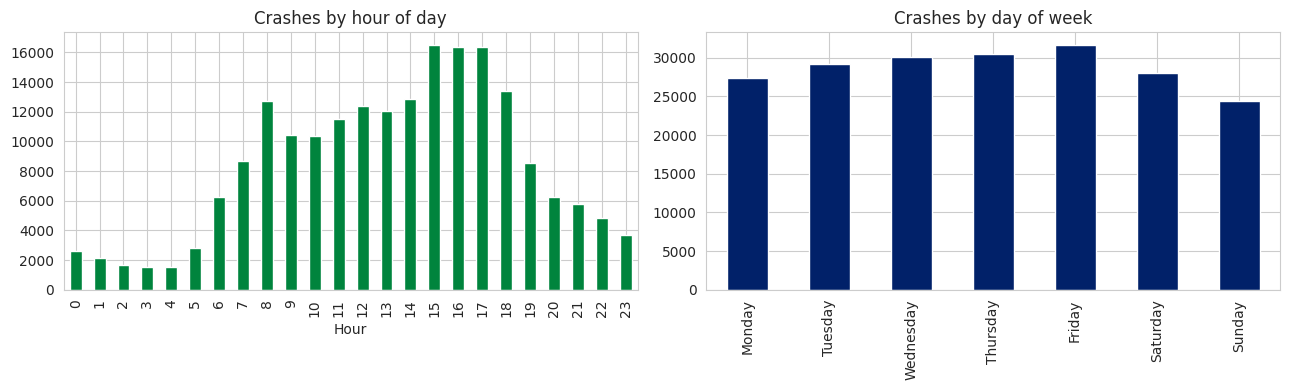

Busiest hours: [15, 16, 17] Busiest Day: ['Friday']


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df.groupby('hour').size().plot(kind='bar', ax=axes[0], color='#00843D')
axes[0].set_title('Crashes by hour of day')
axes[0].set_xlabel('Hour')

order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['day_name'].value_counts().reindex(order).plot(kind='bar', ax=axes[1], color='#012169')
axes[1].set_title('Crashes by day of week')
axes[1].set_xlabel('')
plt.tight_layout()
plt.show()

print('Busiest hours:', df['hour'].value_counts().head(3).index.tolist(), 'Busiest Day:', df['day_name'].value_counts().head(1).index.tolist())

In [ ]:
df['night'] = (df['hour'] >= 22) | (df['hour'] <= 5)
rate = df.groupby('night')['FATALITY'].apply(lambda s: (s > 0).mean() * 100).round(2)
print('Share of crashes that are fatal (%):')
print(rate.rename({False: 'Daytime', True: 'Night (10pm-5am)'}))

Share of crashes that are fatal (%):
night
Daytime             1.51
Night (10pm-5am)    3.28
Name: FATALITY, dtype: float64


**Finding:** Crashes peak at 3 to 5 pm, with a smaller peak at 8 am. They are lowest between 1 and 4 am. Fridays are the busiest day and Sundays the quietest. Night crashes are fewer but a bigger share of them are fatal.

##5.4 What makes a crash more serious?

In [ ]:
def fatal_rate(col, min_count=500):
  g = df.groupby(col).agg(crashes = ('ACCIDENT_NO', 'count'), fatal = ('FATALITY', lambda s: (s > 0).sum()))
  g = g[g['crashes'] >= min_count]
  g['fatal_rate'] = (g['fatal'] / g['crashes'] * 100).round(1)
  return g.sort_values('fatal_rate', ascending=False)

fatal_rate('speed')

,crashes,fatal,fatal_rate
speed,,,
110.0,2089,108,5.2
100.0,28356,1371,4.8
90.0,507,22,4.3
80.0,30535,587,1.9
70.0,12593,194,1.5
60.0,65589,685,1.0
50.0,33118,297,0.9
40.0,13010,76,0.6


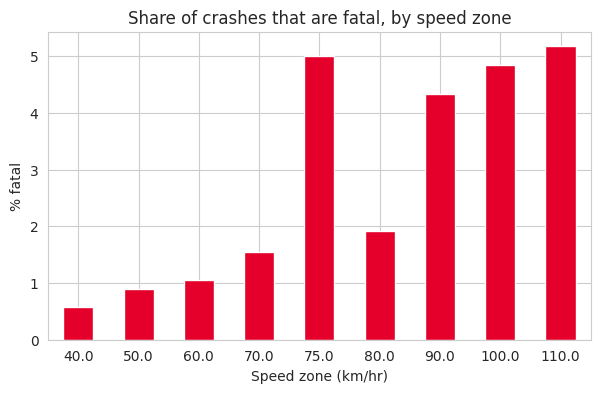

In [ ]:
sp = df[df['speed'].notna() & (df['speed'] >= 40) & (df['speed'] <= 110)]
sp = sp.groupby('speed')['FATALITY'].apply(lambda s: (s > 0).mean() * 100)
ax = sp.plot(kind='bar', color='#E4002B', figsize=(7, 4))
ax.set_title('Share of crashes that are fatal, by speed zone')
ax.set_ylabel('% fatal')
ax.set_xlabel('Speed zone (km/hr)')
plt.xticks(rotation=0)
plt.show()

In [ ]:
fatal_rate('ACCIDENT_TYPE')

,crashes,fatal,fatal_rate
ACCIDENT_TYPE,,,
Collision with a fixed object,30061,1193,4.0
Struck Pedestrian,16569,524,3.2
Fall from or in moving vehicle,1288,20,1.6
Vehicle overturned (no collision),9330,116,1.2
Collision with vehicle,131234,1466,1.1
collision with some other object,2100,20,1.0
No collision and no object struck,8240,50,0.6
Struck animal,2229,13,0.6


In [ ]:
fatal_rate('RMA')

,crashes,fatal,fatal_rate
RMA,,,
Unknown,7601,208,2.7
Arterial Highway,34798,768,2.2
Arterial Other,72877,1231,1.7
Freeway,16089,234,1.5
Local Road,69824,963,1.4


In [ ]:
fatal_rate('ROAD_GEOMETRY')

,crashes,fatal,fatal_rate
ROAD_GEOMETRY,,,
Not at intersection,104318,2384,2.3
T intersection,45524,520,1.1
Cross intersection,46448,458,1.0
Multiple intersection,3821,35,0.9
Y intersection,673,3,0.4


In [ ]:
fatal_rate('DEG_URBAN_NAME')

,crashes,fatal,fatal_rate
DEG_URBAN_NAME,,,
RURAL_VICTORIA,42214,1780,4.2
SMALL_TOWNS,1829,41,2.2
TOWNS,6201,113,1.8
SMALL_CITIES,10355,126,1.2
LARGE_PROVINCIAL_CITIES,11508,112,1.0
MELB_URBAN,125819,1226,1.0
MELBOURNE_CBD,2433,7,0.3
Unknown,910,0,0.0


In [ ]:
fatal_rate('LIGHT_CONDITION')

,crashes,fatal,fatal_rate
LIGHT_CONDITION,,,
Dark No street lights,10539,569,5.4
Dark Street lights on,30836,531,1.7
Day,134992,2024,1.5
Dusk/Dawn,16592,223,1.3
Dark Street lights unknown,2309,18,0.8
Unk.,5564,27,0.5


**Findings:**
- Faster roads are deadlier. The share of fatal crashes rises sharply from 60 km/hr up to 100 and 110 km/hr
- Pedestrians struck by vehicles and crashes with fixed objects are the most deadly crash types
- Dark roads with no street lights are more deadly than daytime
- Rural Victoria has a much higher share of fatal crashes than Melbourne, even though Melbourne has more crashes
- Roads where there was no intersection had the most crashes with the highest fatality rate

##5.5 Which road users are most at risk?

In [ ]:
users = ['PEDESTRIAN', 'BICYCLIST', 'MOTORCYCLIST', 'OLD_PED_65_AND_OVER', 'OLD_DRIVER_75_AND_OVER', 'YOUNG_DRIVER_18_25']
rows = []
for u in users:
    has = df[u] > 0
    rows.append({'road user': u,
                 'crashes involving them': has.sum(),
                 '% fatal': round((df.loc[has, 'FATALITY'] > 0).mean() * 100, 2)})
rows.append({'road user': 'ALL CRASHES', 'crashes involving them': len(df),
             '% fatal': round((df['FATALITY'] > 0).mean() * 100, 2)})
pd.DataFrame(rows).set_index('road user').sort_values('% fatal', ascending=False)

,crashes involving them,% fatal
road user,,
OLD_PED_65_AND_OVER,3609,6.54
PEDESTRIAN,17639,3.17
OLD_DRIVER_75_AND_OVER,13529,2.79
MOTORCYCLIST,28271,2.23
ALL CRASHES,201269,1.69
YOUNG_DRIVER_18_25,54433,1.34
BICYCLIST,19518,0.77


**Finding:** Crashes that involve pedestrians, older pedestrians (65+), motorcyclists and older drivers (75+) are more often fatal than the average crash. Young drivers (18 to 25) are in many crashes (about 55,000) but those crashes are slightly less often fatal than average. Bicyclists are involved in many crashes too, and those are rarely fatal.

##5.6 Where do crashes happen?

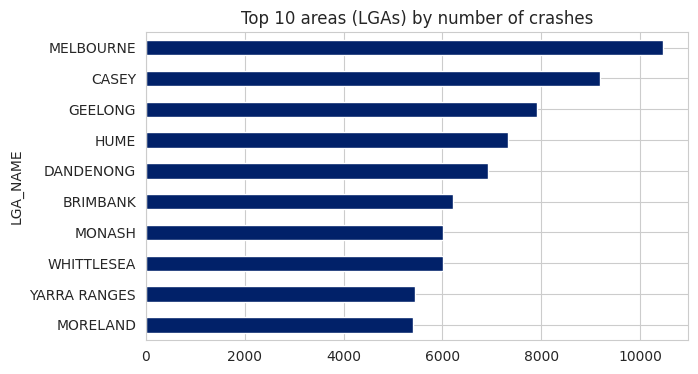

,count
LGA_NAME,
MELBOURNE,10455
CASEY,9180
GEELONG,7921
HUME,7337
DANDENONG,6925
BRIMBANK,6208
MONASH,6018
WHITTLESEA,6006
YARRA RANGES,5445


In [ ]:
top = df['LGA_NAME'].value_counts().head(10)
ax = top.sort_values().plot(kind='barh', color='#012169', figsize=(7, 4))
ax.set_title('Top 10 areas (LGAs) by number of crashes')
plt.show()
top

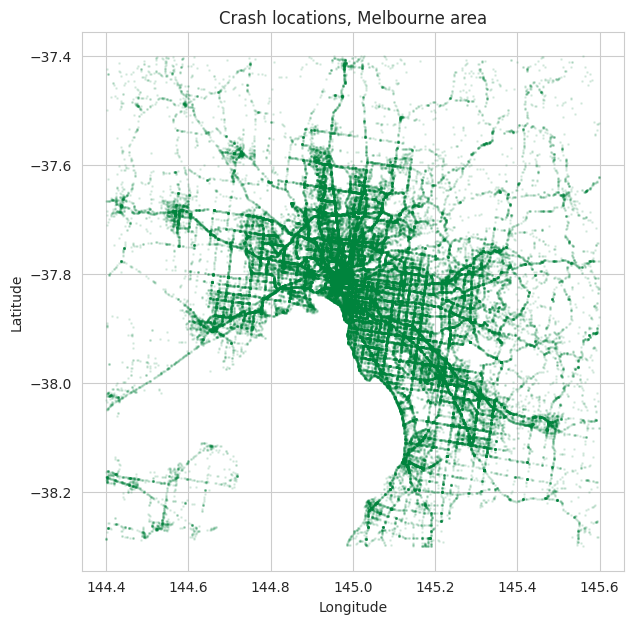

Crashes in the Melbourne box: 144534 of 201269


In [ ]:
mel = df[(df['LATITUDE'].between(-38.3, -37.4)) & (df['LONGITUDE'].between(144.4, 145.6))]
plt.figure(figsize=(7, 7))
plt.scatter(mel['LONGITUDE'], mel['LATITUDE'], s=1, alpha=0.1, color='#00843D')
plt.title('Crash locations, Melbourne area')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()
print('Crashes in the Melbourne box:', len(mel), 'of', len(df))

**Finding:** Crashes cluster along the main roads into Melbourne and in the inner suburbs, so hotspots will be easy to find with DBSCAN. The City of Melbourne, Casey, Geelong and Hume have the most crashes. A rough Melbourne box (about 144,500 of the 201,000 crashes with a location) holds around 72% of all crashes, so we can start with the Melbourne area to keep the work small.

#6. Summary

1. The dataset is fairly clean, with no duplicates and a few missing values.
2. All of our research questions can be answered from this dataset.
3. The crashes run from January 2012 to March 2026.
4. Severity has 3 real levels (fatal, serious injury, other injury), but fatal is only 1.7%
5. 1,275 crashes have no location, and about 1,190 of them are from 2025.